Milestone 1 CIE – Video Game Sale

**Project Overview**

This project focuses on analyzing a Video game sales dataset using Python and the Pandas library. The dataset contains retail transaction details, including customer information, product categories, prices, quantities, payment methods, locations, and transaction dates.

**Objectives**

-load and understand the video game sales dataset.

-Explore rows, columns, data types, and sone numeric information.

-Identify and handle missing values.

-Perform data cleaning and transformation.

-Analyze rank and Sales done in countries.

-Generate meaningful insights from the dataset.

-Create visualizations to present the findings.

**Tools and Technologies**

->Python

->Google Colab

->Pandas

->NumPy

->Matplotlib

->Seaborn

**Dataset Information**

Dataset name: Video game sales

File name: vgsales.csv

Number of rows: 16598

Number of columns: 11



**Expected Outcome**

The project aims to clean, explore, and analyze video game sales data to identify useful  insights and present the findings through visualizations.

Load the video game sale CSV file into a Pandas DataFrame.

In [164]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [165]:
df=pd.read_csv('/content/vgsales.csv')

In [166]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


Check the number of rows and columns in the dataset.

In [167]:
df.shape

(16598, 11)

Display all column names in the dataset.

In [168]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

Display the statistical summary of numerical columns

In [169]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


Check the data types and non-null values of each column.

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


Identify the missing values in each column.



In [171]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


Handle missing values by filling numerical columns with their mean values.

In [172]:
df['Year'] = df['Year'].fillna(df['Year'].mean())

print("Missing numerical values handled successfully!")

Missing numerical values handled successfully!


Fill missing categorical values with the most frequent value.

In [173]:
df['Publisher'] = df['Publisher'].fillna(df['Publisher'].mode()[0])
print("Missing categorical values handled successfully!")

Missing categorical values handled successfully!


Check whether any missing values remain after data cleaning.

In [174]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,0
Genre,0
Publisher,0
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


In [175]:
df['Platform'].dtype

dtype('O')

Display the cleaned dataset to verify the changes.

In [176]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


Calculating the total sum of Europe Sales.

In [177]:
Games_sold = df['EU_Sales'].sum()

print("Video game:",Games_sold  )


Video game: 2434.1300000000006


Calculating the rank got in Other countries sales in video game

In [178]:
Genres = df.groupby('Rank')['Other_Sales'].sum().head(30)

print(Genres)


Rank
1      8.46
2      0.77
3      3.31
4      2.96
5      1.00
6      0.58
7      2.90
8      2.85
9      2.26
10     0.47
11     2.75
12     1.92
13     0.71
14     2.15
15     1.79
16     1.67
17     4.14
18    10.57
19     0.55
20     2.05
21     1.37
22     0.42
23     0.46
24     1.38
25     1.78
26     0.50
27     0.82
28     1.18
29     1.16
30     1.32
Name: Other_Sales, dtype: float64


Analyze the types Genre and number of Platform

---



In [179]:
Gener_counts = df['Genre'].value_counts()

print(Gener_counts)

Platform_counts = df['Platform'].value_counts()

print(Platform_counts)




Genre
Action          3316
Sports          2346
Misc            1739
Role-Playing    1488
Shooter         1310
Adventure       1286
Racing          1249
Platform         886
Simulation       867
Fighting         848
Strategy         681
Puzzle           582
Name: count, dtype: int64
Platform
DS      2163
PS2     2161
PS3     1329
Wii     1325
X360    1265
PSP     1213
PS      1196
PC       960
XB       824
GBA      822
GC       556
3DS      509
PSV      413
PS4      336
N64      319
SNES     239
XOne     213
SAT      173
WiiU     143
2600     133
NES       98
GB        98
DC        52
GEN       27
NG        12
SCD        6
WS         6
3DO        3
TG16       2
GG         1
PCFX       1
Name: count, dtype: int64


Visualize total platform in a each Genre using a bar chart.

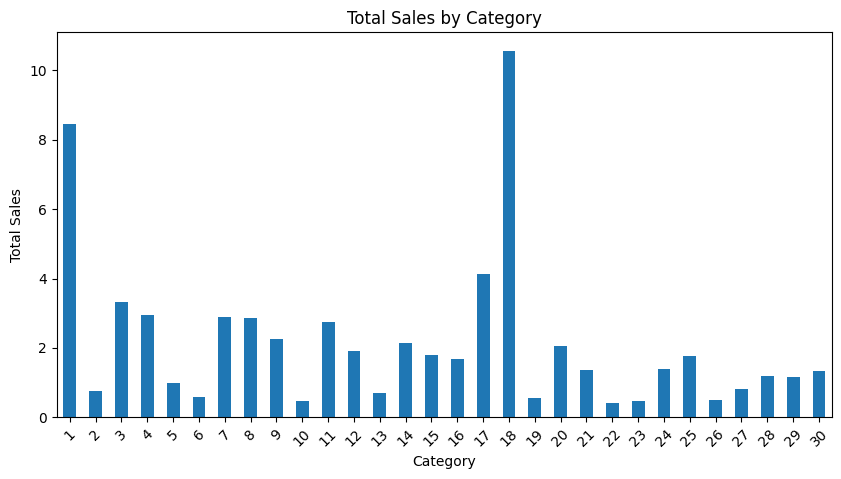

In [180]:
Genres.plot(kind='bar', figsize=(10, 5))

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Visualizing the different Genre using a pie chart.



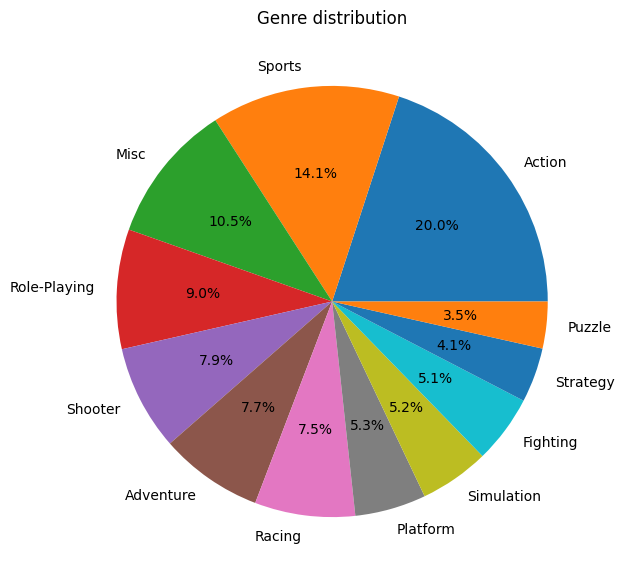

In [181]:
Gener_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))

plt.title('Genre distribution')
plt.ylabel('')
plt.show()


Compare Genre between Global_Sales

In [182]:
Overall_sold = df.groupby('Genre')['Global_Sales'].sum()

print(Overall_sold)

Genre
Action          1751.18
Adventure        239.04
Fighting         448.91
Misc             809.96
Platform         831.37
Puzzle           244.95
Racing           732.04
Role-Playing     927.37
Shooter         1037.37
Simulation       392.20
Sports          1330.93
Strategy         175.12
Name: Global_Sales, dtype: float64


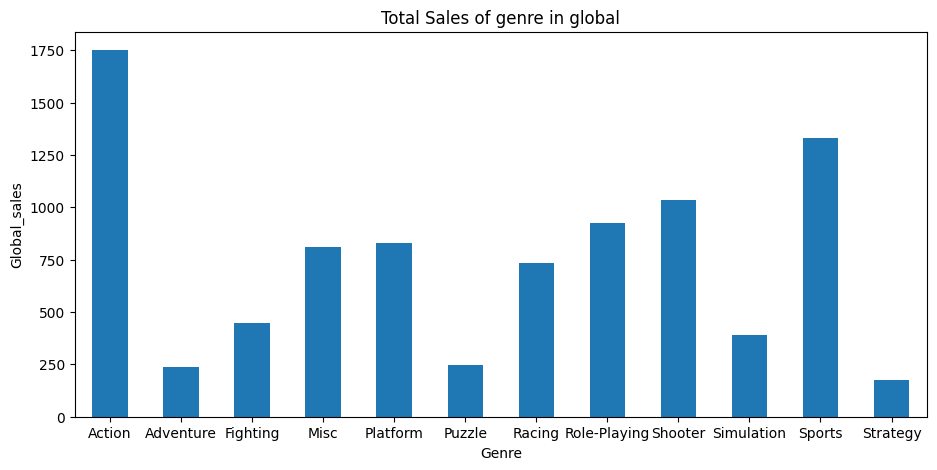

In [183]:
Overall_sold.plot(kind='bar', figsize=(11, 5))

plt.title('Total Sales of genre in global')
plt.xlabel('Genre')
plt.ylabel('Global_sales')
plt.xticks(rotation=0)
plt.show()

Visualize the 10 sales in Other_sales

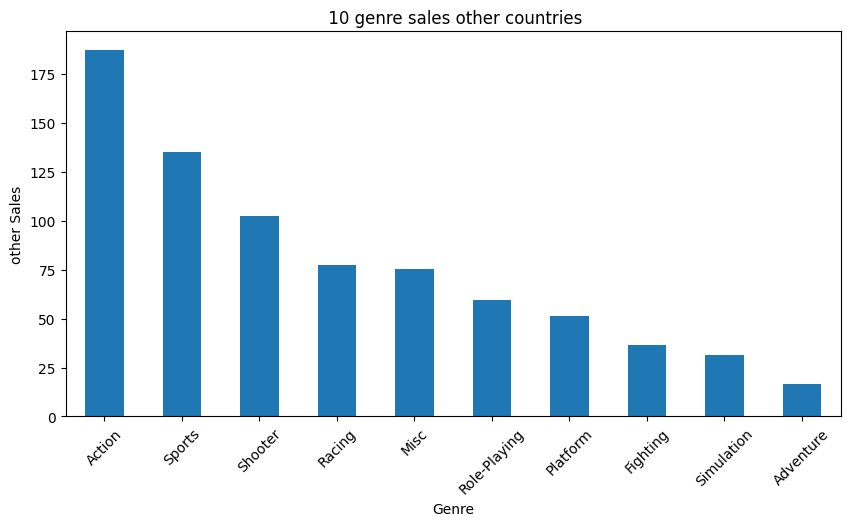

In [184]:
item_sales = df.groupby('Genre')['Other_Sales'].sum().sort_values(ascending=False).head(10)

item_sales.plot(kind='bar', figsize=(10, 5))

plt.title(' 10 genre sales other countries')
plt.xlabel('Genre')
plt.ylabel('other Sales')
plt.xticks(rotation=45)
plt.show()

Analyze the rank distribution using a box plot.

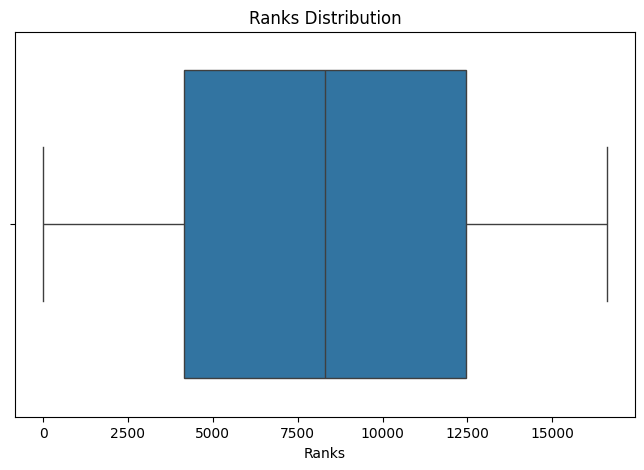

In [185]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Rank'])

plt.title('Ranks Distribution')
plt.xlabel('Ranks')
plt.show()

Study the relationship between of global_Sales in a year

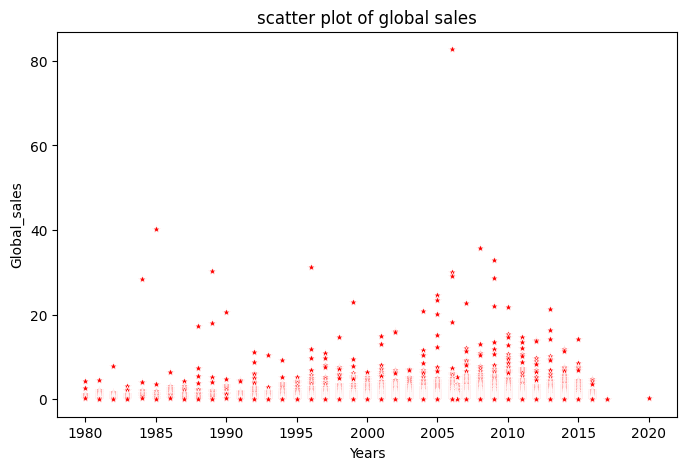

In [186]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Year', y='Global_Sales',marker='*',color='Red')

plt.title('scatter plot of global sales')
plt.xlabel('Years')
plt.ylabel('Global_sales')
plt.show()

Analyze the relationship between platfrom more used in a year using a scatter plot.



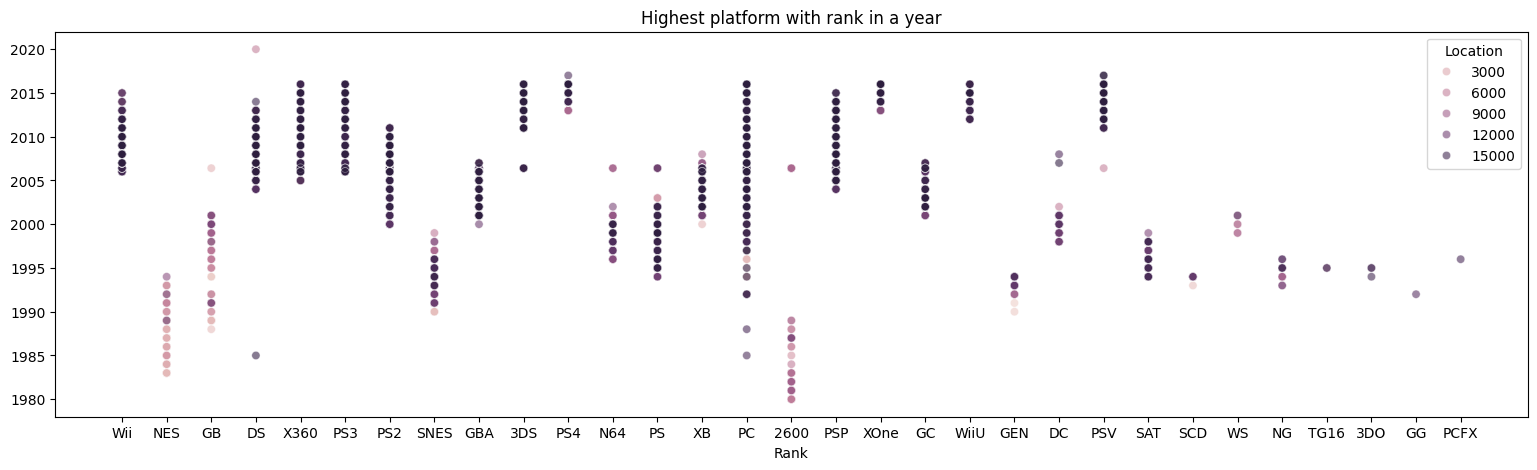

In [187]:
plt.figure(figsize=(19, 5))

sns.scatterplot(
    data=df,
    x='Platform',
    y='Year',
    hue='Rank',
    alpha=0.6
)

plt.title('Highest platform with rank in a year')
plt.xlabel('Rank')
plt.ylabel('')
plt.legend(title='Location')
plt.show()

Visualize the correlation between Countries sales using a heatmap.

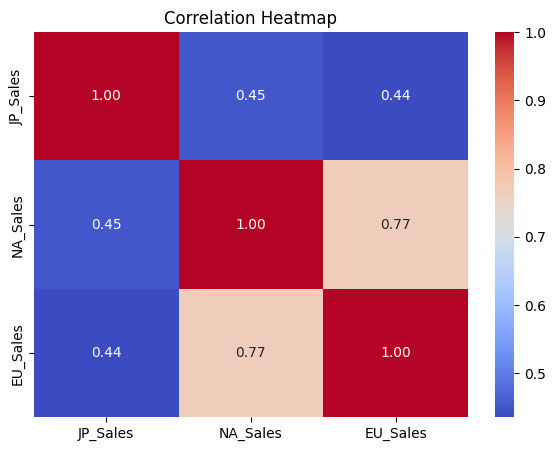

In [188]:
plt.figure(figsize=(7, 5))

correlation = df[['JP_Sales', 'NA_Sales', 'EU_Sales']].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

**Conclusion**

This project analyzed video game sale sales data using Python, Pandas, Matplotlib, and Seaborn.

Data cleaning techniques were used to handle missing values and prepare the dataset for analysis.

Different visualizations helped to understand rank ditributed to genre other platform.

The analysis provided useful insights into retail sales performance and customer purchasing behavior.

This project improved my understanding of data analysis, data visualization.

In [189]:
df.to_csv('Video_game_sales.csv', index=False)